## Import

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Setup

In [2]:
assert os.path.exists("weights_V1_3/regression_pytorch_kfold_metrics.json"), "run regression_pytorch_V1_3.ipynb first"
SEED = 42
np.random.seed(SEED)
os.makedirs("weights_V1_3", exist_ok=True)

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()
print("cleaned:", df.shape, "| Income median:", round(df["Income"].median()))

REG_FEATURES = [
    "NumCatalogPurchases", "MntMeatProducts", "MntWines", "NumWebVisitsMonth",
    "MntSweetProducts", "MntFruits", "NumWebPurchases", "MntGoldProds",
    "NumStorePurchases", "MntFishProducts", "Kidhome", "Age", "NumDealsPurchases",
]
X_full = df[REG_FEATURES].values
y_full = df["Income"].astype(float).values
print(f"features: {len(REG_FEATURES)} dims (all numeric)")

cleaned: (2212, 28) | Income median: 51371
features: 13 dims (all numeric)


## Dataloader

In [4]:
class NumpyDataset:
    def __init__(self, X, y):
        self.X = np.asarray(X, dtype=np.float64)
        self.y = np.asarray(y, dtype=np.float64).reshape(-1, 1)
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return self.X[i], self.y[i]

In [5]:
def batch_generator(ds, batch_size=64, shuffle=True, rng=None):
    idx = np.arange(len(ds))
    if shuffle:
        idx = rng.permutation(idx)
    for s in range(0, len(ds), batch_size):
        b = idx[s:s + batch_size]
        yield ds.X[b], ds.y[b]

## Model

In [6]:
class ScratchDeepMLP:
    def __init__(self, in_dim=13, h=64, p=0.2, seed=42):
        rng = np.random.default_rng(seed)
        self.W1 = rng.standard_normal((in_dim, h)) * np.sqrt(2.0 / in_dim)
        self.b1 = np.zeros(h)
        self.g1 = np.ones(h); self.s1 = np.zeros(h)
        self.rm1 = np.zeros(h); self.rv1 = np.ones(h)
        self.W2 = rng.standard_normal((h, h)) * np.sqrt(2.0 / h)
        self.b2 = np.zeros(h)
        self.g2 = np.ones(h); self.s2 = np.zeros(h)
        self.rm2 = np.zeros(h); self.rv2 = np.ones(h)
        self.W3 = rng.standard_normal((h, 1)) * np.sqrt(2.0 / h)
        self.b3 = np.zeros(1)
        self.p = p
        self.drng = np.random.default_rng(seed + 1)
        self.adam = {n: [np.zeros_like(getattr(self, n)), np.zeros_like(getattr(self, n))]
                     for n in ("W1", "b1", "g1", "s1", "W2", "b2", "g2", "s2", "W3", "b3")}
        self.t = 0
    def _bn(self, x, g, s, rm, rv, train, mom=0.1, eps=1e-5):
        if train:
            B = len(x); mu = x.mean(axis=0); va = x.var(axis=0)
            rm[:] = (1 - mom) * rm + mom * mu
            rv[:] = (1 - mom) * rv + mom * (va * B / max(B - 1, 1))
            xh = (x - mu) / np.sqrt(va + eps)
            cache = (x, xh, mu, va)
        else:
            xh = (x - rm) / np.sqrt(rv + eps); cache = None
        return g * xh + s, cache
    @staticmethod
    def _bn_backward(dout, cache, g, eps=1e-5):
        x, xh, mu, va = cache; N = len(x)
        dg = (dout * xh).sum(axis=0); db = dout.sum(axis=0)
        dxh = dout * g
        ivar = 1.0 / np.sqrt(va + eps)
        dvar = (dxh * (x - mu) * -0.5 * (va + eps) ** -1.5).sum(axis=0)
        dmu = (dxh * -ivar).sum(axis=0) + dvar * (-2.0 * (x - mu)).mean(axis=0)
        dx = dxh * ivar + dvar * 2.0 * (x - mu) / N + dmu / N
        return dx, dg, db
    def forward(self, X, train):
        Z1 = X @ self.W1 + self.b1
        B1, c1 = self._bn(Z1, self.g1, self.s1, self.rm1, self.rv1, train)
        A1 = np.maximum(0, B1)
        m1 = (self.drng.random(A1.shape) >= self.p) / (1 - self.p) if train else None
        D1 = A1 * m1 if train else A1
        Z2 = D1 @ self.W2 + self.b2
        B2, c2 = self._bn(Z2, self.g2, self.s2, self.rm2, self.rv2, train)
        S = B2 + D1
        A2 = np.maximum(0, S)
        m2 = (self.drng.random(A2.shape) >= self.p) / (1 - self.p) if train else None
        D2 = A2 * m2 if train else A2
        out = D2 @ self.W3 + self.b3
        return {"Z1": Z1, "c1": c1, "A1": A1, "m1": m1, "D1": D1, "Z2": Z2,
                "c2": c2, "S": S, "A2": A2, "m2": m2, "D2": D2, "out": out}
    def predict(self, X):
        return self.forward(X, train=False)["out"].ravel()
    def backward(self, dout, c, Xb):
        dW3 = c["D2"].T @ dout; db3 = dout.sum(axis=0)
        dD2 = dout @ self.W3.T
        dA2 = dD2 * (c["m2"] if c["m2"] is not None else 1.0)
        dS = dA2 * (c["S"] > 0)
        dB2, dg2, ds2 = self._bn_backward(dS, c["c2"], self.g2)
        dW2 = c["D1"].T @ dB2; db2 = dB2.sum(axis=0)
        dD1 = dB2 @ self.W2.T + dS
        dA1 = dD1 * (c["m1"] if c["m1"] is not None else 1.0)
        dZ1, dg1, ds1 = self._bn_backward(dA1 * (c["A1"] > 0), c["c1"], self.g1)
        dW1 = Xb.T @ dZ1; db1 = dZ1.sum(axis=0)
        return {"W3": dW3, "b3": db3, "W2": dW2, "b2": db2, "g2": dg2, "s2": ds2,
                "W1": dW1, "b1": db1, "g1": dg1, "s1": ds1}
    def adam_step(self, grads, lr, wd=1e-4, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        for name, g in grads.items():
            g = g + wd * getattr(self, name)
            m, v = self.adam[name]
            m[:] = b1 * m + (1 - b1) * g
            v[:] = b2 * v + (1 - b2) * g * g
            mhat = m / (1 - b1 ** self.t); vhat = v / (1 - b2 ** self.t)
            getattr(self, name).__isub__(lr * mhat / (np.sqrt(vhat) + eps))

## Training

In [7]:
K = 5
LR0, BATCH = 1e-3, 64

kf = KFold(n_splits=K, shuffle=True, random_state=SEED)
fold_rows = []
for fold, (tr_idx, va_idx) in enumerate(kf.split(X_full), start=1):
    Xtr_f, Xva_f = X_full[tr_idx], X_full[va_idx]
    ytr_f, yva_f = y_full[tr_idx], y_full[va_idx]
    sc_f = StandardScaler().fit(Xtr_f)
    Xtr_fs, Xva_fs = sc_f.transform(Xtr_f).astype(np.float64), sc_f.transform(Xva_f).astype(np.float64)
    ysc_f = StandardScaler().fit(ytr_f.reshape(-1, 1))
    MU_f, SIG_f = float(ysc_f.mean_[0]), float(ysc_f.scale_[0])
    ytr_fz = ysc_f.transform(ytr_f.reshape(-1, 1)).ravel().astype(np.float64)
    m = ScratchDeepMLP(in_dim=len(REG_FEATURES), h=64, p=0.2, seed=SEED + fold)
    rng_f = np.random.default_rng(SEED + fold)
    train_ds_f = NumpyDataset(Xtr_fs, ytr_fz)
    for epoch in range(100):
        lr = 0.5 * LR0 * (1 + np.cos(np.pi * epoch / 100))
        for xb, yb in batch_generator(train_ds_f, BATCH, True, rng_f):
            B = len(xb)
            c = m.forward(xb, train=True)
            dpred = 2.0 * (c["out"] - yb) / B
            m.adam_step(m.backward(dpred, c, xb), lr)
    pred_z = m.predict(Xva_fs)
    pred_raw = pred_z.ravel() * SIG_f + MU_f
    mse_f = float(mean_squared_error(yva_f, pred_raw))
    fold_rows.append({
        "fold": fold,
        "test_loss_MSE_raw": round(mse_f, 1),
        "rmse": round(float(np.sqrt(mse_f)), 1),
        "mae": round(float(mean_absolute_error(yva_f, pred_raw)), 1),
        "r2": round(float(r2_score(yva_f, pred_raw)), 4),
    })
    print(f"fold {fold}: RMSE={fold_rows[-1]['rmse']:.1f} R2={fold_rows[-1]['r2']:.4f}")

fold 1: RMSE=10294.2 R2=0.7769


fold 2: RMSE=11566.7 R2=0.7005


fold 3: RMSE=9334.7 R2=0.8057


fold 4: RMSE=11529.0 R2=0.7303


fold 5: RMSE=10097.7 R2=0.7729


## K-Fold Summary

In [8]:
kfold_df = pd.DataFrame(fold_rows)
summary = {k: {"mean": round(float(kfold_df[k].mean()), 4), "std": round(float(kfold_df[k].std()), 4)}
           for k in ("test_loss_MSE_raw", "rmse", "mae", "r2")}
print(kfold_df.to_string(index=False))
print(json.dumps(summary, indent=2))
with open("weights_V1_3/regression_scratch_kfold_metrics.json", "w") as f:
    json.dump({"k": K, "folds": fold_rows, "summary": summary}, f, indent=2)

 fold  test_loss_MSE_raw    rmse    mae     r2
    1        105969684.8 10294.2 6513.9 0.7769
    2        133789233.2 11566.7 7066.1 0.7005
    3         87135854.0  9334.7 6680.2 0.8057
    4        132917303.0 11529.0 7166.4 0.7303
    5        101962592.9 10097.7 7061.8 0.7729
{
  "test_loss_MSE_raw": {
    "mean": 112354933.58,
    "std": 20414543.5782
  },
  "rmse": {
    "mean": 10564.46,
    "std": 966.7002
  },
  "mae": {
    "mean": 6897.68,
    "std": 283.7674
  },
  "r2": {
    "mean": 0.7573,
    "std": 0.0416
  }
}


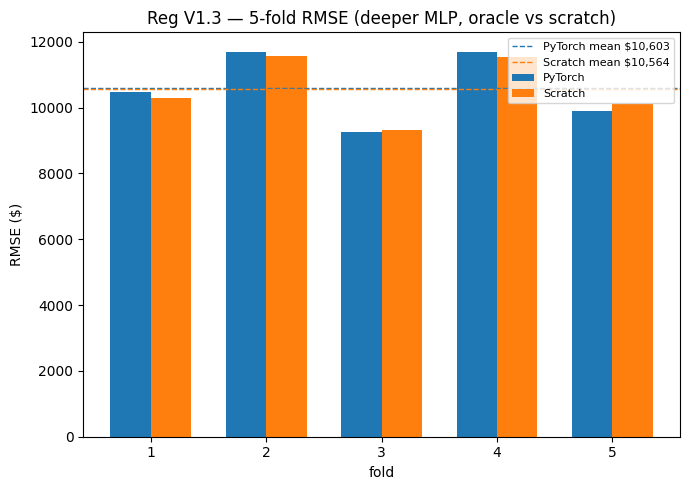

PyTorch RMSE mean+-std: 10602.88 1080.143
Scratch RMSE mean+-std: 10564.46 966.7002


In [9]:
import matplotlib.pyplot as plt

pyt_kf = json.load(open("weights_V1_3/regression_pytorch_kfold_metrics.json"))
scr_kf = json.load(open("weights_V1_3/regression_scratch_kfold_metrics.json"))
pyt_rmse = [r["rmse"] for r in pyt_kf["folds"]]
scr_rmse = [r["rmse"] for r in scr_kf["folds"]]
folds_x = np.arange(1, K + 1)
width = 0.35
plt.figure(figsize=(7, 5))
plt.bar(folds_x - width / 2, pyt_rmse, width, label="PyTorch")
plt.bar(folds_x + width / 2, scr_rmse, width, label="Scratch")
plt.axhline(pyt_kf["summary"]["rmse"]["mean"], color="C0", linestyle="--", linewidth=1,
            label=f"PyTorch mean ${pyt_kf['summary']['rmse']['mean']:,.0f}")
plt.axhline(scr_kf["summary"]["rmse"]["mean"], color="C1", linestyle="--", linewidth=1,
            label=f"Scratch mean ${scr_kf['summary']['rmse']['mean']:,.0f}")
plt.xticks(folds_x); plt.xlabel("fold"); plt.ylabel("RMSE ($)")
plt.title("Reg V1.3 — 5-fold RMSE (deeper MLP, oracle vs scratch)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("media/kfold_reg_V1_3.png", dpi=150)
plt.show()

print("PyTorch RMSE mean+-std:", pyt_kf["summary"]["rmse"]["mean"], pyt_kf["summary"]["rmse"]["std"])
print("Scratch RMSE mean+-std:", scr_kf["summary"]["rmse"]["mean"], scr_kf["summary"]["rmse"]["std"])